生成网格...

开始对比实验 (Runs: 30)
Run  | Neal (ℓ0-CS DLE) (m) | DSB (MindQuantum) (m) | Mosek (ℓ1-CS DLE) (m)
-----------------------------------------------------------------------------------------------
1    | 2.7245          | 2.7364               | 10.9014        
2    | 4.5519          | 2.4892               | 10.6051        
3    | 6.9647          | 2.9139               | 6.9365         
4    | 3.3090          | 2.2555               | 10.1044        
5    | 3.1500          | 2.3916               | 12.0712        
6    | 1.9752          | 2.9317               | 7.6692         
7    | 1.7343          | 2.7477               | 8.5351         
8    | 1.7848          | 2.9167               | 8.2518         
9    | 2.9585          | 2.6415               | 11.5352        
10   | 0.9891          | 2.5776               | 3.7687         
11   | 1.4070          | 3.2366               | 12.0416        
12   | 3.5294          | 2.3623               | 9.6690         
13   | 2.6248          | 2.1682  

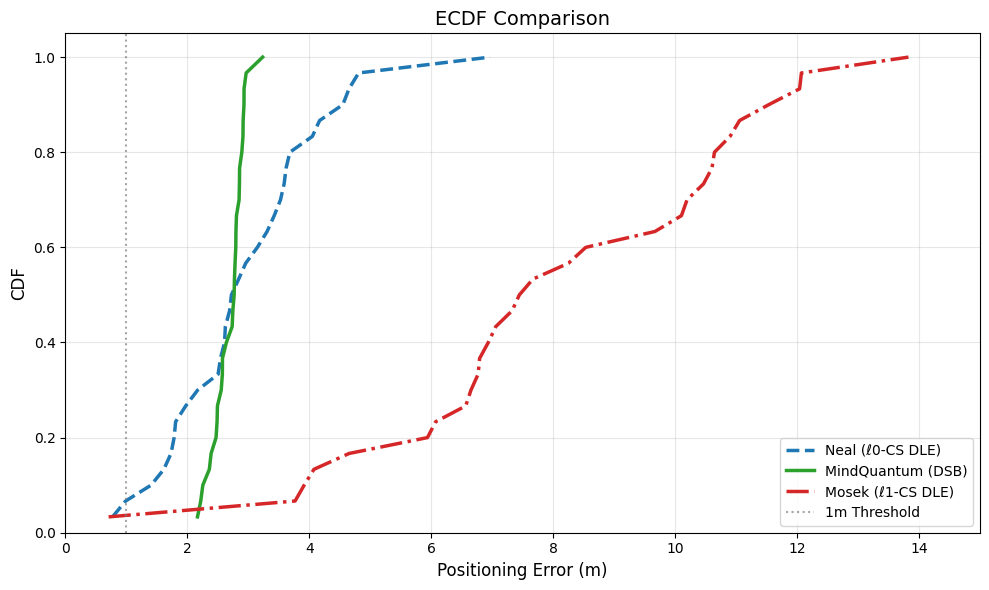

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import speed_of_light
from scipy.sparse import csr_matrix
from pyqubo import Binary
import neal
import cvxpy as cp
import time

# ==========================================
# 0. MindQuantum 算法部分,来自mindquantum DSB源代码
# ==========================================

class DSB:
    """
    Discrete Simulated Bifurcation (DSB) 算法
    """
    def __init__(self, J, h=None, n_iter=500, batch_size=50, dt=0.8, 
                 alpha=0.1, beta=0.01, temperature=0.1, noise_scale=0.05):
        """
        参数:
            J: 相互作用矩阵
            h: 磁场向量
            n_iter: 迭代次数
            batch_size: 批次大小
            dt: 时间步长
            alpha: 动量衰减系数
            beta: 随机扰动强度
            temperature: 模拟退火温度
            noise_scale: 噪声尺度
        """
        self.J = csr_matrix(J)
        self.h = h.reshape(-1, 1) if h is not None else np.zeros((J.shape[0], 1))
        self.N = J.shape[0]
        self.n_iter = n_iter
        self.batch_size = batch_size
        self.dt = dt
        self.alpha = alpha
        self.beta = beta
        self.temperature = temperature
        self.noise_scale = noise_scale
        
        # 泵浦参数
        self.p = np.linspace(0, 1, n_iter)
        self.delta = 1.0
        
        # 计算xi
        j_sq_sum = self.J.power(2).sum()
        if j_sq_sum == 0: 
            j_sq_sum = 1.0
        self.xi = 0.5 * np.sqrt(self.N - 1) / np.sqrt(j_sq_sum)
        
        # 初始化
        self.initialize()
    
    def initialize(self):
        """随机初始化"""
        self.x = np.zeros((self.N, self.batch_size))
        self.y = np.zeros((self.N, self.batch_size))
        
        # 为每个batch使用不同的初始化
        for b in range(self.batch_size):
            # 混合使用不同的初始化策略
            if b % 3 == 0:
                # 策略1: 均匀分布
                self.x[:, b] = 2 * (np.random.rand(self.N) - 0.5)
            elif b % 3 == 1:
                # 策略2: 高斯分布
                self.x[:, b] = 0.1 * np.random.randn(self.N)
            else:
                # 策略3: 混合分布
                mask = np.random.rand(self.N) > 0.5
                self.x[:, b] = np.where(mask, 0.2 * (np.random.rand(self.N) - 0.5), 0)
            
            self.y[:, b] = 0.01 * np.random.randn(self.N)
    
    def soft_sign(self, x, T=0.1):
        """软sign函数"""
        return np.tanh(x / T) + self.beta * np.random.randn(*x.shape)
    
    def update(self):
        """更新步骤"""
        # 温度衰减
        T_decay = np.exp(-np.linspace(0, 3, self.n_iter))
        
        for i in range(self.n_iter):
            # 当前温度
            current_T = self.temperature * T_decay[i]
            
            # 1. 计算force
            sign_x = self.soft_sign(self.x, current_T)
            interaction = self.J.dot(sign_x)
            
            force = -(self.delta - self.p[i]) * self.x + self.xi * (interaction + self.h)
            
            # 2. 增加随机扰动
            noise = self.noise_scale * np.random.randn(self.N, self.batch_size)
            force += noise * current_T
            
            # 3. 更新动量
            self.y = (1 - self.alpha) * self.y + force * self.dt
            
            # 4. 更新位置
            self.x += self.dt * self.y * self.delta
            
            # 5. 边界限制
            mask = np.abs(self.x) > 1.0
            self.x = np.where(mask, np.sign(self.x) * (1 - 0.1 * np.random.rand(*mask.shape)), self.x)
            
            # 6. 动量衰减
            self.y *= (1 - 0.01)
    
    def get_solutions(self):
        """获取解决方案"""
        solutions = []
        energies = []
        
        for b in range(self.batch_size):
            x_b = self.x[:, b]
            # 使用自适应阈值
            threshold = np.percentile(np.abs(x_b), 70)
            spin = np.where(np.abs(x_b) > threshold, np.sign(x_b), 0)
            
            # 确保有激活的点
            if np.sum(np.abs(spin)) == 0:
                top_k = min(5, self.N // 10)
                indices = np.argsort(np.abs(x_b))[-top_k:]
                spin[indices] = np.sign(x_b[indices])
            
            # 转换为{0, 1}
            bits = (spin + 1) / 2
            solutions.append(bits)
            
            # 计算能量
            energy = -0.5 * np.dot(spin.T, self.J.dot(spin)) - np.dot(self.h.flatten(), spin)
            energies.append(energy)
        
        return np.array(solutions).T, np.array(energies)

# ==========================================
# 1. 基础物理与信号模型，来自最初的WINNER TWO 信道模型
# ==========================================

def nearfield_array_manifold(theta, r, M, d, wavelength):   #计算近场阵列流形
    a = np.zeros(M, dtype=complex)
    safe_r = np.maximum(r, 1e-4) 
    for m in range(M):
        phase = -2*np.pi*d*m*np.sin(theta)/wavelength + np.pi*m**2*d**2*np.cos(theta)**2/(wavelength*safe_r)
        a[m] = np.exp(1j*phase)
    return a

def calc_aoa(true_pos, ap_pos):            #计算到达角，通过角度确定位置
    dx = true_pos[0] - ap_pos[0]; dy = true_pos[1] - ap_pos[1]
    theta = np.arctan2(dy, dx)
    return theta + np.pi if dx < 0 else theta

def calc_dist(true_pos, ap_pos):          #计算距离
    return np.hypot(true_pos[0]-ap_pos[0], true_pos[1]-ap_pos[1])

def path_loss(dist, fc):          #计算路径损耗
    d0, n = 1.0, 3.0
    PL0 = 20*np.log10(4*np.pi*d0*fc/speed_of_light)
    return PL0 + 10*n*np.log10(np.maximum(dist, d0)/d0)

def generate_ap_signal(true_pos, ap_pos, M, d, fc, n_clusters=3, n_paths=3, SNR_DB=20):   #每个AP生成信号
    wavelength = speed_of_light/fc
    r_los = calc_dist(true_pos, ap_pos)
    theta_los = calc_aoa(true_pos, ap_pos)
    a_los = nearfield_array_manifold(theta_los, r_los, M, d, wavelength)
    PL_los = path_loss(r_los, fc)
    path_gain = np.sqrt(10**(-PL_los/10))
    y = path_gain * np.exp(1j*2*np.pi*np.random.rand()) * a_los
    
    for _ in range(n_clusters):
        cl_angle = theta_los + np.random.uniform(-np.pi/3, np.pi/3)               #簇NLOS路径生成代码，参考网上模型
        cl_dist  = r_los + np.random.uniform(5, 20)
        for __ in range(n_paths):
            ang = cl_angle + np.random.uniform(-np.pi/12, np.pi/12)
            dst = cl_dist  + np.random.uniform(-2, 2)
            a   = nearfield_array_manifold(ang, dst, M, d, wavelength)
            y  += np.sqrt(10**(-path_loss(dst, fc)/10)) * (np.random.randn()+1j*np.random.randn())/np.sqrt(2) * a
            
    sig_p = np.mean(np.abs(y)**2)
    noise_p = sig_p / (10**(SNR_DB/10))
    y += np.sqrt(noise_p/2) * (np.random.randn(M) + 1j*np.random.randn(M))
    return y[:, None]

def generate_all_signals(true_pos, ap_positions, params):
    return [generate_ap_signal(true_pos, ap, params['M'], params['d'], params['fc'],
                               params['n_clusters'], params['n_paths'], params['SNR_DB'])
            for ap in ap_positions]

def design_grid(ap_positions, G=900):
    grid_size = int(np.sqrt(G))
    x = np.linspace(0, 20, grid_size)
    y = np.linspace(0, 20, grid_size)
    grid = np.column_stack((np.meshgrid(x, y)[0].ravel(), np.meshgrid(x, y)[1].ravel()))[:G]
    return grid

# ==========================================
# 2. ℓ₀-CS DLE 算法，文献中的算法，用neal退火求解器求解对应的QUBO问题
# ==========================================
class L0CSDLELocalizer:
    def __init__(self, ap_positions, grid_points, M=10, d=0.087, fc=2.4e9):
        self.ap_positions = ap_positions
        self.grid_points  = grid_points
        self.G = len(grid_points)
        self.P = len(ap_positions)
        self.M = M; self.d = d; self.fc = fc
        self.wavelength = speed_of_light/fc
        self.psi_matrices = self._build_psi_matrices()
        self.sampler_factory = neal.SimulatedAnnealingSampler 

    def _build_psi_matrices(self):
        psi_list = []
        for ap in self.ap_positions:
            th = np.arctan2(self.grid_points[:,1]-ap[1], self.grid_points[:,0]-ap[0])
            r  = np.maximum(np.hypot(self.grid_points[:,0]-ap[0], self.grid_points[:,1]-ap[1]), 1e-4)
            Psi_ap = np.zeros((self.M, self.G), dtype=complex)
            for g in range(self.G):
                vec = nearfield_array_manifold(th[g], r[g], self.M, self.d, self.wavelength)
                Psi_ap[:, g] = vec / np.linalg.norm(vec) 
            psi_list.append(Psi_ap)
        return psi_list

    def _solve_qubo(self, y_obs, gamma=0.3):
        y_normalized = []
        for y in y_obs:
            norm_val = np.linalg.norm(y)
            y_normalized.append(y / norm_val if norm_val > 1e-9 else y)
        
        yHPsi = [(y.conj().T @ Psi).flatten() for y, Psi in zip(y_normalized, self.psi_matrices)]
        x = [Binary(f'x{i}') for i in range(self.G)]
        lin, quad = 0, 0

        for i in range(self.G):
            coeff = 0
            for p in range(self.P):
                coeff += np.real(yHPsi[p][i])
            lin += -1.0 * coeff * x[i]

        CrossCorr = np.zeros((self.G, self.G))
        for p in range(self.P):
            CrossCorr += np.real(self.psi_matrices[p].conj().T @ self.psi_matrices[p])
            
        for i in range(self.G):
            for j in range(i+1, self.G):
                Wij = gamma * CrossCorr[i, j]
                quad += Wij * x[i] * x[j]
        
        H = lin + quad
        model = H.compile()
        qubo, offset = model.to_qubo()
        sampler = self.sampler_factory()
        sampleset = sampler.sample_qubo(qubo, num_reads=100) 
        best_sample = sampleset.first.sample
        return np.array([best_sample[f'x{i}'] for i in range(self.G)])

    def localize(self, y_obs):
        try:
            x_est = self._solve_qubo(y_obs)
            indices = np.where(x_est > 0.5)[0]
            if len(indices) > 0:
                return self.grid_points[indices].mean(axis=0)
            else:
                return self.grid_points[np.random.randint(0, self.G)]
        except Exception:
            return self.grid_points[np.random.randint(0, self.G)]

# ==========================================
# 3. ℓ₀-CS DLE 算法，但是用mindquantum的DSB算法进行退火求解QUBO问题
# ==========================================
class MindQuantumLocalizer(L0CSDLELocalizer):
    def __init__(self, ap_positions, grid_points, M=10, d=0.087, fc=2.4e9):
        super().__init__(ap_positions, grid_points, M, d, fc)
        self.CrossCorr = np.zeros((self.G, self.G))
        for p in range(self.P):
             self.CrossCorr += np.real(self.psi_matrices[p].conj().T @ self.psi_matrices[p])
    
    def _qubo_to_ising(self, linear_coeffs, quad_matrix):
        """QUBO 转 Ising 模型"""
        N = len(linear_coeffs)
        J = np.zeros((N, N))
        h = np.zeros(N)
        
        # 处理二次项
        for i in range(N):
            for j in range(i+1, N):
                val = quad_matrix[i, j]
                if abs(val) > 1e-9:
                    J[i, j] = val * 0.25
                    J[j, i] = val * 0.25
                    h[i] += val * 0.25
                    h[j] += val * 0.25
        
        # 处理线性项
        h += linear_coeffs * 0.5
        
        return J, h
    
    def _solve_dsb(self, y_obs, gamma=0.3, num_repeats=5):
        """使用DSB算法求解"""
        # 1. 预处理数据
        y_normalized = []
        for y in y_obs:
            norm_val = np.linalg.norm(y)
            y_normalized.append(y / norm_val if norm_val > 1e-9 else y)
        
        # 2. 构建QUBO系数
        linear_coeffs = np.zeros(self.G)
        yHPsi = [(y.conj().T @ Psi).flatten() for y, Psi in zip(y_normalized, self.psi_matrices)]
        
        for i in range(self.G):
            coeff = sum(np.real(yHPsi[p][i]) for p in range(self.P))
            linear_coeffs[i] = -1.0 * coeff 
        
        Q_upper = np.triu(self.CrossCorr, k=1) * gamma
        
        # 3. 转换为Ising模型
        J_ising, h_ising = self._qubo_to_ising(linear_coeffs, Q_upper)
        
        best_solution = None
        best_energy = float('inf')
        
        # 4. 多次运行DSB，增加随机性 ， 此处增加随机性为的是生成不同的误差，不然会一直是一个值
        for repeat in range(num_repeats):
            # 每次使用不同的随机种子
            np.random.seed(int(time.time() * 1000) % (2**32) + repeat * 1000)
            
            # 每次运行使用不同的参数
            if repeat == 0:
                solver = DSB(J_ising, h_ising, n_iter=400, batch_size=60, dt=0.8,
                           alpha=0.1, beta=0.02, temperature=0.15, noise_scale=0.05)
            elif repeat == 1:
                solver = DSB(J_ising, h_ising, n_iter=500, batch_size=40, dt=0.7,
                           alpha=0.15, beta=0.03, temperature=0.2, noise_scale=0.08)
            elif repeat == 2:
                solver = DSB(J_ising, h_ising, n_iter=350, batch_size=80, dt=0.9,
                           alpha=0.08, beta=0.01, temperature=0.1, noise_scale=0.03)
            else:
                solver = DSB(J_ising, h_ising, n_iter=450, batch_size=50, dt=0.75,
                           alpha=0.12, beta=0.025, temperature=0.18, noise_scale=0.06)
            
            solver.update()
            solutions, energies = solver.get_solutions()
            
            # 找到本次运行的最佳解
            min_idx = np.argmin(energies)
            if energies[min_idx] < best_energy:
                best_energy = energies[min_idx]
                best_solution = solutions[:, min_idx]
        
        return best_solution
    
    def localize(self, y_obs):
        try:
            x_est = self._solve_dsb(y_obs, num_repeats=8)
            
            indices = np.where(x_est > 0.5)[0]
            if len(indices) > 0:
                return self.grid_points[indices].mean(axis=0)
            else:
                return self.grid_points[np.random.randint(0, self.G)]
                
        except Exception:
            return self.grid_points[np.random.randint(0, self.G)]

# ==========================================
# 4. ℓ₁-CS DLE 定位器 (用Mosek求解器求解凸优化问题，求解器需要下载证书到本地文件中)
# ==========================================
class L1CSDLELocalizerMosek:
    def __init__(self, ap_positions, grid_points, M=10, d=0.087, fc=2.4e9, angle_grid_size=180):
        self.ap_positions = ap_positions
        self.grid_points = grid_points
        self.G = len(grid_points)
        self.P = len(ap_positions)
        self.M = M; self.d = d; self.fc = fc
        self.wavelength = speed_of_light/fc
        self.angle_grid = np.linspace(0, 2*np.pi, angle_grid_size, endpoint=False)
        self.M_angle = angle_grid_size
        self.LOS_dicts, self.NLOS_dicts = self._build_dictionaries()

    def _build_dictionaries(self):
        LOS_dicts = []
        NLOS_dicts = []
        for ap in self.ap_positions:
            LOS_dict = np.zeros((self.M, self.G), dtype=complex)
            for g in range(self.G):
                theta = calc_aoa(self.grid_points[g], ap)
                r = np.maximum(calc_dist(self.grid_points[g], ap), 1e-4)
                LOS_dict[:, g] = nearfield_array_manifold(theta, r, self.M, self.d, self.wavelength)
            LOS_dicts.append(LOS_dict)
            NLOS_dict = np.zeros((self.M, self.M_angle), dtype=complex)
            for a in range(self.M_angle):
                NLOS_dict[:, a] = nearfield_array_manifold(self.angle_grid[a], 100.0, self.M, self.d, self.wavelength)
            NLOS_dicts.append(NLOS_dict)
        return LOS_dicts, NLOS_dicts

    def localize(self, y_obs):
        SCALER = 1e5 
        y_scaled = [y * SCALER for y in y_obs]
        total_signal_power = np.mean([np.mean(np.abs(y)**2) for y in y_scaled])
        avg_noise_power = total_signal_power / 100.0 
        from scipy import stats
        dof = 2 * self.P * self.M
        epsilon = (avg_noise_power / 2) * stats.chi2.ppf(0.95, dof) * 1.1 
        X = cp.Variable((self.G, self.P), complex=True)
        Y_list = [cp.Variable(self.M_angle, complex=True) for _ in range(self.P)]
        objective = cp.Minimize(np.sqrt(self.P) * cp.sum(cp.norm(X, 2, axis=1)) + sum(cp.norm(Y_list[l], 1) for l in range(self.P)))
        constraints = []
        total_sq_error = 0
        for l in range(self.P):
            z_hat = self.LOS_dicts[l] @ X[:, l] + self.NLOS_dicts[l] @ Y_list[l]
            total_sq_error += cp.sum_squares(y_scaled[l].flatten() - z_hat)
        constraints.append(total_sq_error <= epsilon)
        prob = cp.Problem(objective, constraints)
        try:
            prob.solve(solver=cp.MOSEK, verbose=False)
        except cp.error.SolverError:
            pass
        if prob.status in [cp.OPTIMAL, cp.OPTIMAL_INACCURATE] and X.value is not None:
            position_scores = np.linalg.norm(X.value, axis=1)
            top_k = 3
            top_indices = np.argsort(position_scores)[-top_k:]
            top_scores = position_scores[top_indices]
            if np.sum(top_scores) > 1e-9:
                weights = top_scores / np.sum(top_scores)
                return np.average(self.grid_points[top_indices], axis=0, weights=weights)
            else:
                return self.grid_points[np.argmax(position_scores)]
        else:
            return self.grid_points[np.random.randint(0, self.G)]

# ==========================================
# 5. 主程序 (Run & Plot)
# ==========================================

if __name__ == "__main__":
    params = dict(M=10, d=0.087, fc=2.4e9, n_clusters=3, n_paths=3, SNR_DB=20)
    ap_positions = np.array([[0, 20], [20, 15], [12, 0]])
    true_pos = [9.0, 8.0]

    print("生成网格...")
    grid = design_grid(ap_positions, G=900)
    
    l0_neal = L0CSDLELocalizer(ap_positions, grid, **{k: params[k] for k in ['M', 'd', 'fc']})
    l0_mind = MindQuantumLocalizer(ap_positions, grid, **{k: params[k] for k in ['M', 'd', 'fc']})
    l1_mosek = L1CSDLELocalizerMosek(ap_positions, grid, **{k: params[k] for k in ['M', 'd', 'fc']})

    n_runs = 30
    errors_neal = []
    errors_mind = []
    errors_mosek = []

    print(f"\n开始对比实验 (Runs: {n_runs})")
    print("=" * 95)
    print(f"{'Run':<4} | {'Neal (ℓ0-CS DLE) (m)':<15} | {'DSB (MindQuantum) (m)':<20} | {'Mosek (ℓ1-CS DLE) (m)':<15}")
    print("-" * 95)

    for run in range(n_runs):
        # 设置随机种子
        seed = run * 1000 + int(time.time()) % 10000
        np.random.seed(seed)
        
        y_obs = generate_all_signals(true_pos, ap_positions, params)

        # 1. Neal
        try:
            p_n = l0_neal.localize(y_obs)
            e_n = np.linalg.norm(p_n - true_pos)
        except:
            e_n = 15.0
        errors_neal.append(e_n)

        # 2. MindQuantum DSB
        try:
            p_m = l0_mind.localize(y_obs)
            e_m = np.linalg.norm(p_m - true_pos)
        except Exception:
            e_m = 15.0
        errors_mind.append(e_m)

        # 3. Mosek
        try:
            p_cvx = l1_mosek.localize(y_obs)
            e_cvx = np.linalg.norm(p_cvx - true_pos)
        except:
            e_cvx = 15.0
        errors_mosek.append(e_cvx)

        # 显示每一次运行的误差
        print(f"{run+1:<4} | {e_n:<15.4f} | {e_m:<20.4f} | {e_cvx:<15.4f}")

    # 计算统计信息
    print("=" * 95)
    print(f"{'Algorithm':<20} | {'Mean':<10} | {'Std':<10} | {'Median':<10} | {'Min':<10} | {'Max':<10}")
    print("-" * 95)
    
    for name, errors in [('Neal (ℓ0-CS DLE)', errors_neal), 
                         ('DSB (MindQuantum)', errors_mind), 
                         ('Mosek (ℓ1-CS DLE)', errors_mosek)]:
        mean_err = np.mean(errors)
        std_err = np.std(errors)
        median_err = np.median(errors)
        min_err = np.min(errors)
        max_err = np.max(errors)
        
        print(f"{name:<20} | {mean_err:<10.4f} | {std_err:<10.4f} | {median_err:<10.4f} | {min_err:<10.4f} | {max_err:<10.4f}")

    # 绘制ECDF图
    plt.figure(figsize=(10, 6))
    
    style_map = [
        (errors_neal, 'Neal (ℓ0-CS DLE)', '#1f77b4', '--'),
        (errors_mind, 'MindQuantum (DSB)', '#2ca02c', '-'),
        (errors_mosek, 'Mosek (ℓ1-CS DLE)', '#d62728', '-.')
    ]

    for errors, label, c, ls in style_map:
        sorted_errors = np.sort(errors)
        cdf = np.arange(1, len(sorted_errors)+1) / len(sorted_errors)
        plt.plot(sorted_errors, cdf, linewidth=2.5, label=label, color=c, linestyle=ls)

    plt.axvline(x=1.0, color='gray', linestyle=':', label='1m Threshold', alpha=0.7)
    plt.xlabel('Positioning Error (m)', fontsize=12)
    plt.ylabel('CDF', fontsize=12)
    plt.title('ECDF Comparison', fontsize=14)
    plt.grid(True, alpha=0.3)
    plt.legend(fontsize=10)
    plt.xlim(0, 15)
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()